In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from pptx import Presentation
from pptx.util import Inches
import openpyxl
import matplotlib as mpl
import streamlit as st

# 1. HIPÓTESIS
Con los datos recogidos vamos a realizar un estudio de mercado basado principalmente las ventas de videojuegos a nivel global y por regiones según el género de videojuegos.
* Análisis de ventas de videojuegos según la platarforma a nivel global y por regiones
* Análisis de ventas de videojuegos según el fabricante de la consola a nivel global y por regiones
* Análisis de ventas de los videojuegos más vendidos a nivel global y por regiones
* Análisis de ventas de videojuegos según su género a nivel global y por regiones
* Análisis de ventas de videojuegos según su género a lo largo de los años, a nivel global y por regiones


# 2. ANÁLISIS DE DATOS

In [2]:
archivo = '../data/videojuegos.csv'
df = pd.read_csv(archivo)
df.head()

,Game,Platform,Manufacturer,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,PS4,Sony,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,PS4,Sony,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,PS4,Sony,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,PS4,Sony,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,PS4,Sony,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


In [3]:
df['Year'] = df['Year'].astype('Int64')

## Análisis descriptivo

In [4]:
df[['North America','Europe','Japan','Rest of World','Global']].describe()

,North America,Europe,Japan,Rest of World,Global
count,23178.000000,23178.000000,23178.000000,23178.000000,23178.000000
mean,0.292838,0.179921,0.072677,0.059235,0.604891
std,0.868053,0.596062,0.307926,0.203402,1.723504
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.010000,0.000000,0.000000,0.000000,0.060000
50%,0.090000,0.030000,0.000000,0.010000,0.190000
75%,0.270000,0.140000,0.030000,0.050000,0.540000
max,41.490000,29.020000,10.220000,10.570000,82.740000


In [5]:
game_sales = (df.groupby('Game')['Global'].sum().sort_values(ascending=False))

top10_games = game_sales.head(10).sum()

total_sales = game_sales.sum()

(top10_games / total_sales) * 100

np.float64(5.853428206240157)

In [6]:
game_sales.head(20)

Game
Wii Sports                        165.27
Grand Theft Auto V                140.60
Call of Duty: Black Ops 3          73.46
Mario Kart Wii                     71.34
Wii Sports Resort                  65.77
Call of Duty: Ghosts               62.02
Call of Duty: Black Ops            61.85
Call of Duty: Modern Warfare 3     61.42
New Super Mario Bros.              59.81
Call of Duty: Black Ops II         59.12
Wii Play                           57.94
New Super Mario Bros. Wii          56.94
Call of Duty: Advanced Warfare     56.64
Call of Duty: Modern Warfare 2     50.04
Nintendogs                         49.43
Minecraft                          47.89
Mario Kart DS                      46.63
The Elder Scrolls V: Skyrim        45.62
Wii Fit                            45.42
Super Mario Bros.                  45.31
Name: Global, dtype: float64

In [7]:
df['Game'].nunique()

12263

In [8]:
len(df)

23178

Con estos datos podemos concluir que las ventas por videojuegos están muy influidas por la existencia de ventas de un mismo videojuego en diferentes plataformas.
Por lo que tendremos que realizar un análisis de ventas según el videojuego a nivel mundial y por regiones, para ver cuáles son las franquicias de videojuegos más vendidas.

## Ventas según el videoguego a nivel Mundial y por Regiones

In [9]:
games_df = (df.groupby('Game').agg({'Global': 'sum','North America': 'sum','Europe': 'sum','Japan': 'sum','Rest of World': 'sum'}).reset_index())

In [10]:
top_games = (games_df.sort_values(by='Global',ascending=False).head(20))

top_games

,Game,Global,North America,Europe,Japan,Rest of World
11741,Wii Sports,165.27,82.85,57.98,7.54,16.91
3962,Grand Theft Auto V,140.60,58.06,59.42,3.42,19.71
1326,Call of Duty: Black Ops 3,73.46,34.95,27.14,1.30,10.03
5934,Mario Kart Wii,71.34,31.53,25.64,7.58,6.60
11743,Wii Sports Resort,65.77,31.36,21.94,6.56,5.91
1329,Call of Duty: Ghosts,62.02,33.57,20.44,1.01,6.97
1325,Call of Duty: Black Ops,61.85,35.16,18.85,1.18,6.67
1332,Call of Duty: Modern Warfare 3,61.42,31.12,22.44,1.24,6.64
7137,New Super Mario Bros.,59.81,22.66,18.37,13.00,5.78
1327,Call of Duty: Black Ops II,59.12,28.16,21.89,1.44,7.64


Aunque a nivel global, el videojuego más vendido es el Wii Sports, seguido de Gran Theft Auto V. En este top de los 20 videojuegos más vendidos, se puede ver que la franquicia Call of Duty es la más vendida.

C:\Users\bgran\AppData\Local\Temp\ipykernel_23692\3920951005.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


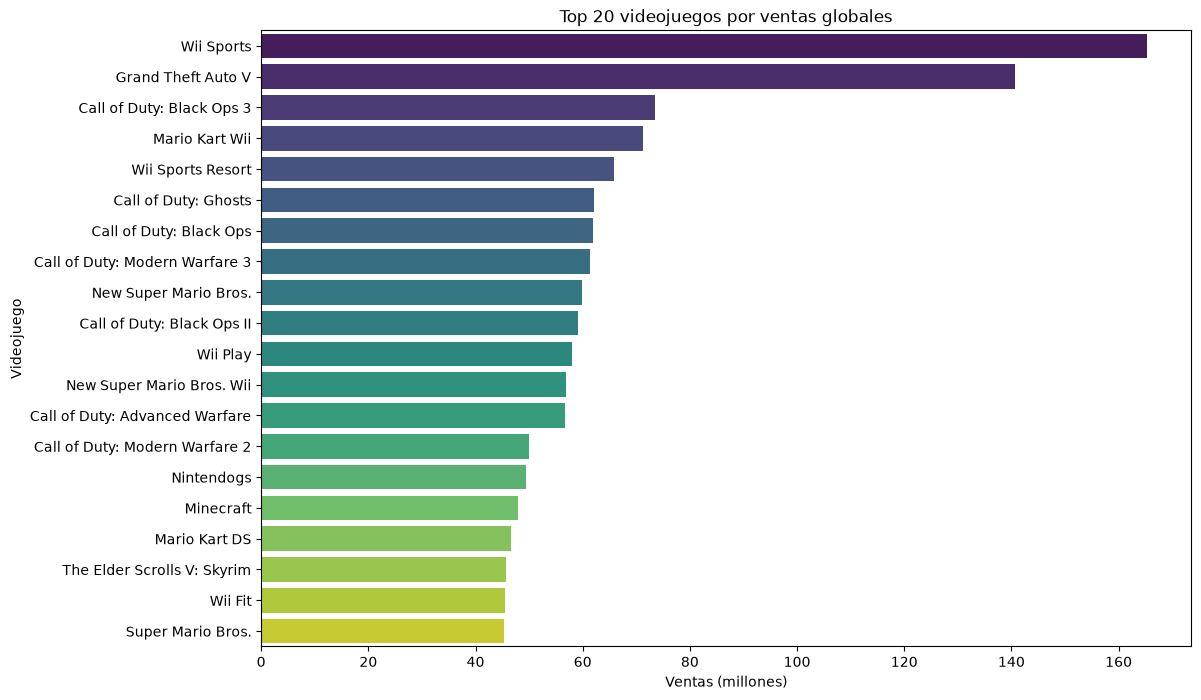

In [11]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=top_games,
    x='Global',
    y='Game',
    palette='viridis'
)

plt.title('Top 20 videojuegos por ventas globales')
plt.xlabel('Ventas (millones)')
plt.ylabel('Videojuego')

plt.show()

In [12]:
for n in [10, 20]:
    
    porcentaje = (games_df.nlargest(n, 'Global')['Global'].sum()/ games_df['Global'].sum()* 100)
    
    print(f"Top {n}: {porcentaje:.2f}%")

Top 10: 5.85%
Top 20: 9.43%


Con estos datos podemos ver que el top 10 y el top 20 de los videojuegos más vendidos a nivel global, representa no llega al 6% ni al 10%, respectivamente.

In [13]:
games_df.nlargest(10,'North America')[['Game', 'North America']]

,Game,North America
11741,Wii Sports,82.85
3962,Grand Theft Auto V,58.06
1325,Call of Duty: Black Ops,35.16
1326,Call of Duty: Black Ops 3,34.95
1329,Call of Duty: Ghosts,33.57
9931,Super Mario Bros.,32.48
5934,Mario Kart Wii,31.53
11743,Wii Sports Resort,31.36
1332,Call of Duty: Modern Warfare 3,31.12
5229,Kinect Adventures!,29.97


In [14]:
games_df.nlargest(10,'Europe')[['Game', 'Europe']]

,Game,Europe
3962,Grand Theft Auto V,59.42
11741,Wii Sports,57.98
3119,FIFA 15,30.30
3120,FIFA 16,30.25
1326,Call of Duty: Black Ops 3,27.14
5934,Mario Kart Wii,25.64
3121,FIFA 17,24.57
1332,Call of Duty: Modern Warfare 3,22.44
3118,FIFA 14,22.10
7213,Nintendogs,21.95


In [15]:
games_df.nlargest(10,'Japan')[['Game', 'Japan']]

,Game,Japan
7137,New Super Mario Bros.,13.00
7796,Pokemon Diamond/Pokemon Pearl,12.08
7790,Pokemon Black/Pokemon White,11.30
388,Animal Crossing: Wild World,10.66
1100,Brain Age 2: More Training in Minutes a Day,10.64
7811,Pokemon Red/Pokemon Blue,10.22
7140,New Super Mario Bros. Wii,9.40
387,Animal Crossing: New Leaf,8.75
2643,Dragon Quest IX: Sentinels of the Starry Skies,8.70
7820,Pokemon X/Pokemon Y,8.69


Con este último análisis, podemos concluir que los gustos de Norte América y Europa son más similares, ya que coinciden en los videojuegos de Wii Sports y la franquicia de Call of Duty. Aunque en Norte América, les gusta más los juegos de la franquicia de Super Mario Bros y en Europa prefieren la franquicia de la FIFA. Sin embargo, en Japon prefieren la franquicia de Pokemon, Animal Crossing y Super Mario Bros diferiendo mucho de los gustos de Norte América y Europa.

In [16]:
## Curva de Pareto
pareto = (games_df['Global'].sort_values(ascending=False).cumsum()/ games_df['Global'].sum()* 100)

sales = games_df['Global'].sort_values(ascending=False)

pareto = sales.cumsum() / sales.sum() * 100

videojuegos_pct = (np.arange(1, len(sales) + 1)/ len(sales)* 100)

indice_80 = np.argmax(pareto >= 80)

pct_videojuegos = ((indice_80 + 1)/ len(sales)* 100)

pct_videojuegos


np.float64(16.35815053412705)

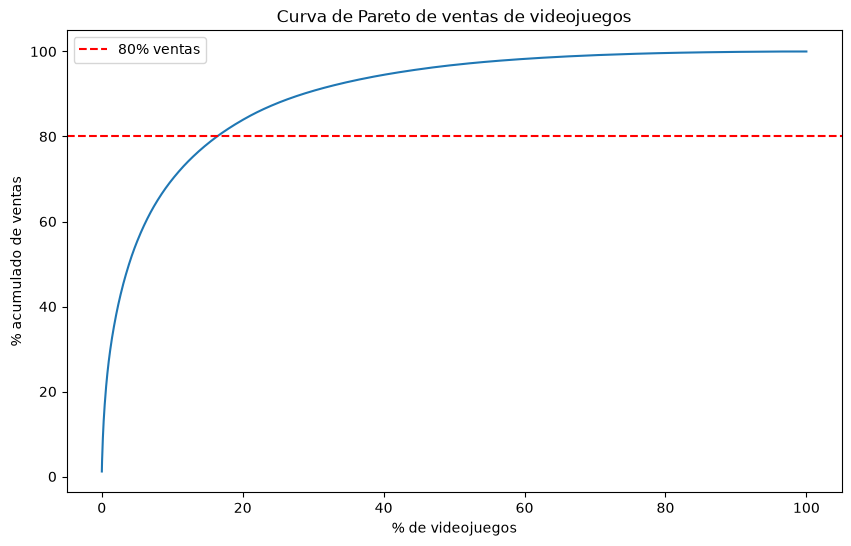

In [17]:
plt.figure(figsize=(10,6))

plt.plot(videojuegos_pct, pareto)

plt.axhline(80,
            color='red',
            linestyle='--',
            label='80% ventas')

plt.xlabel('% de videojuegos')
plt.ylabel('% acumulado de ventas')
plt.title('Curva de Pareto de ventas de videojuegos')
plt.legend()

plt.show()

La curva de Pareto muestra una elevada concentración de las ventas en un número reducido de títulos. Concretamente, el 16,36% de los videojuegos acumula el 80% de las ventas globales. Esto indica que la industria está fuertemente dominada por un grupo relativamente pequeño de videojuegos superventas, mientras que la mayoría de los títulos tienen una contribución mucho más limitada al volumen total de ventas.

En consencuencia, las ventas de videojuegos no se distribuyen de forma uniforme. Un reducido grupo de títulos acumula la mayor parte del mercado, mientras que la mayoría de videojuegos presentan volúmenes de venta considerablemente más bajos.

## Ventas de Videojuegos Según la Plataforma a nivel Mundial y por Regiones

Analizar:

Ventas totales
Número de juegos por plataforma
Media de ventas por juego

In [18]:
ventas_plataforma = (df.groupby('Platform')['Global'].sum().sort_values(ascending=False).reset_index())

ventas_plataforma.head(10)

,Platform,Global
0,PS3,1816.53
1,X360,1782.26
2,Wii,1770.14
3,DS,1469.45
4,PS2,1256.92
5,PS4,1178.39
6,PS,730.68
7,Xbox One,563.77
8,PSP,464.40
9,3DS,445.84


C:\Users\bgran\AppData\Local\Temp\ipykernel_23692\1776870610.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


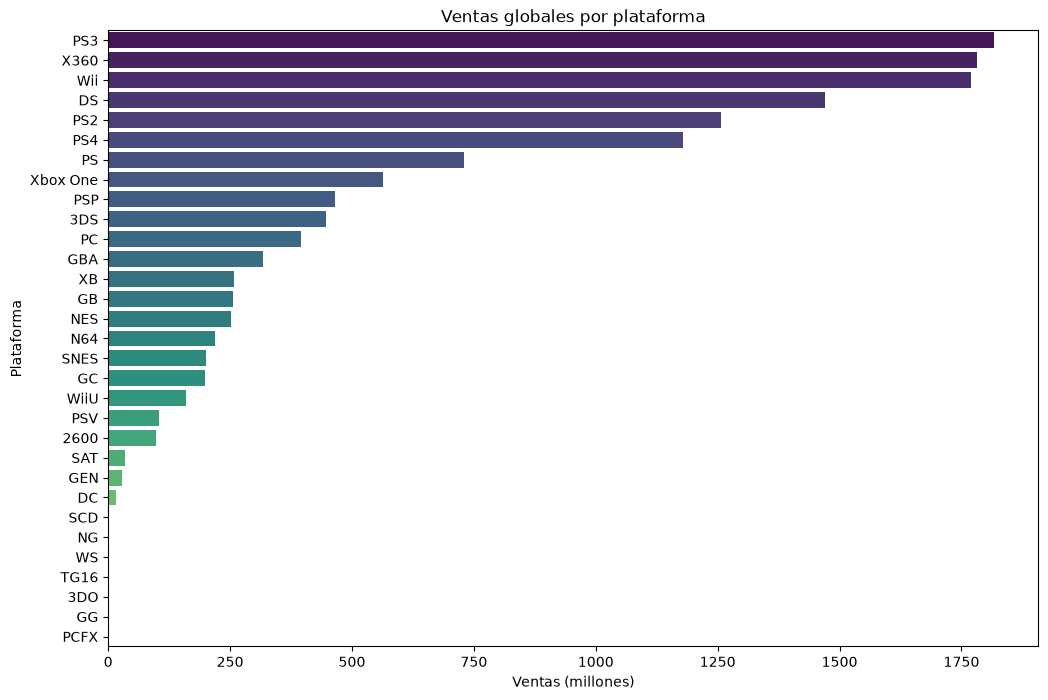

In [19]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=ventas_plataforma,
    x='Global',
    y='Platform',
    palette='viridis'
)

plt.title('Ventas globales por plataforma')
plt.xlabel('Ventas (millones)')
plt.ylabel('Plataforma')

plt.show()

En la gráfica se puede ver como las plataformas PS3, X360 y Wii son las que mayor número de ventas de videojuegos generan. Cada una de ellas pertenece a un fabricante diferente: Sony, Microsoft y Nintendo, respectivamente.

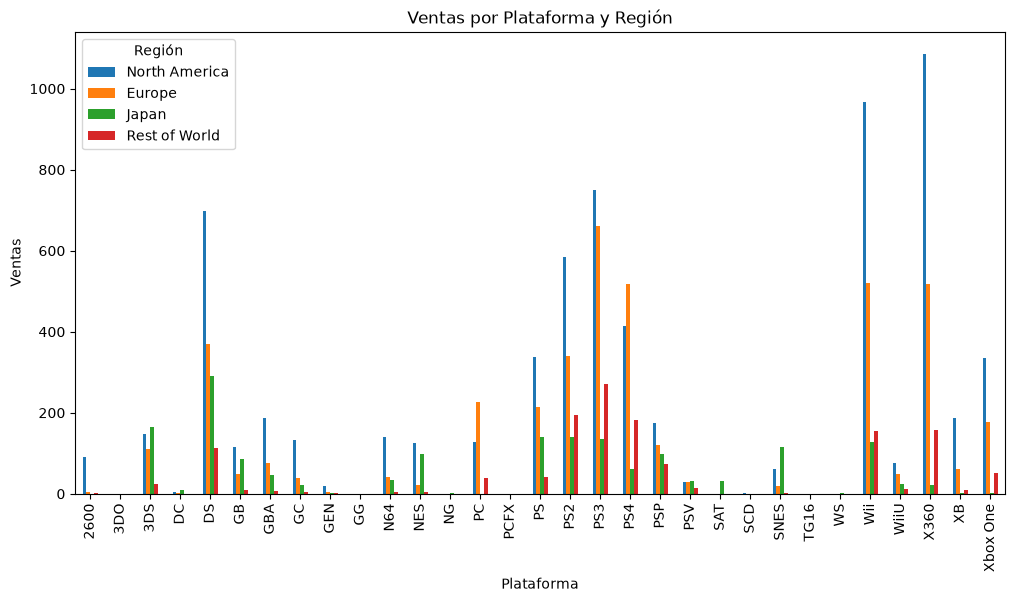

In [20]:
df_plot = df.groupby('Platform')[['North America','Europe','Japan','Rest of World']].sum()

df_plot.plot(kind='bar',figsize=(12,6))

plt.title('Ventas por Plataforma y Región')
plt.xlabel('Plataforma')
plt.ylabel('Ventas')
plt.legend(title='Región')
plt.show()

Cuando se separa las ventas de videojuegos según las plataformas y las regiones, se puede ver que en muchas destaca como mayoritaria las ventas en Norte América como la X360 de Microsoft y la Wii y la DS de Nintendo. Sin embargo, si miramos las plataformas de Sony (Playstation) las ventas por regiones aparecen bastantes más igualadas.

## Ventas de Videojuegos según el Fabricante a nivel Global y por Regiones

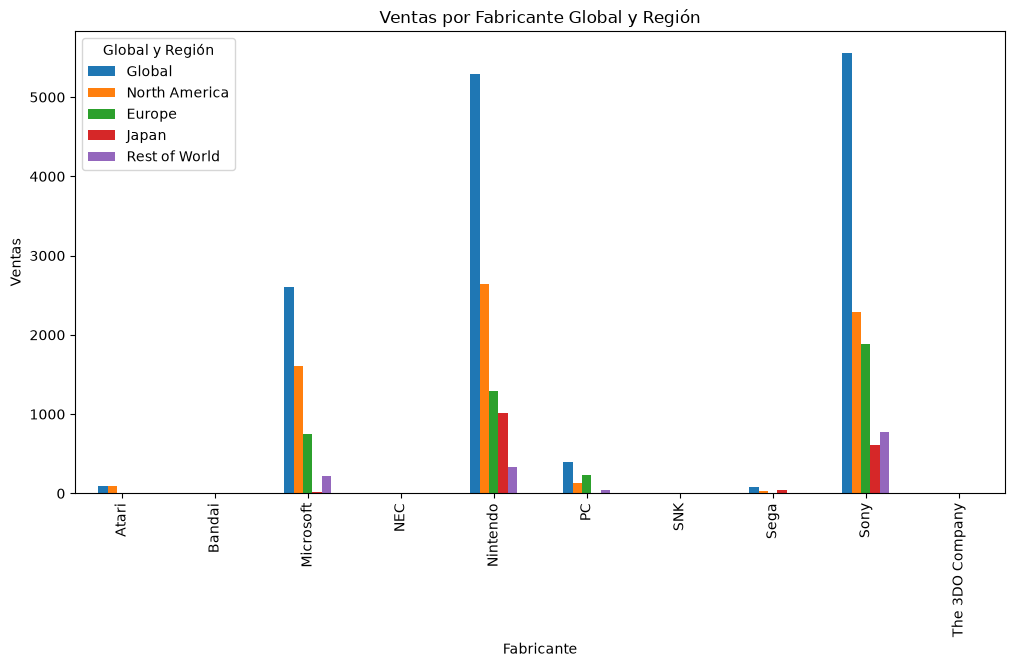

In [21]:
df_plot = df.groupby('Manufacturer')[['Global','North America','Europe','Japan','Rest of World']].sum()

df_plot.plot(kind='bar',figsize=(12,6))

plt.title('Ventas por Fabricante Global y Región')
plt.xlabel('Fabricante')
plt.ylabel('Ventas')
plt.legend(title='Global y Región')
plt.show()

Si analizamos las ventas por fabricante de las plataformas y las comparamos con las ventas globales y por regiones según las plataformas, nos podemos dar cuenta de que las PS3 (Sony), X360 (Microsoft) y Wii (Nintendo) eran quienes dominaban las ventas por plataforma; las ventas de videojuegos por fabricante es dominada claramente por Sony y Nintendo tanto a nivel Global y por Regiones.

## Ventas de Videojuegos por Género a Nivel Mundial y Por Regiones

In [22]:
import squarify

In [26]:
genre_sales = (df.groupby('Genre')['Global'].sum().sort_values(ascending=False))
genre_sales

Genre
Action              2888.03
Sports              2047.85
Shooter             1928.43
Role-Playing        1432.05
Misc                1286.90
Platform            1122.75
Racing              1067.41
Fighting             618.84
Simulation           614.58
Adventure            353.78
Puzzle               334.57
Strategy             229.84
Action-Adventure      79.33
Music                  9.63
MMO                    5.04
Party                  0.65
Visual Novel           0.48
Name: Global, dtype: float64

In [25]:
import plotly.express as px

genre_sales = (
    df.groupby('Genre')['Global']
      .sum()
      .reset_index()
)

fig = px.treemap(
    genre_sales,
    path=['Genre'],
    values='Global',
    color='Global',
    color_continuous_scale='Viridis'
)

fig.update_layout(
    title='Cuota de mercado por género'
)

fig.show()

In [ ]:
genre_sales = (df.groupby('Genre')[['North America','Europe','Japan','Rest of World','Global']].sum().sort_values('Global', ascending=False))

genre_sales

,North America,Europe,Japan,Rest of World,Global
Genre,,,,,
Action,1407.69,921.51,231.21,326.16,2888.03
Sports,1023.24,642.96,162.03,219.03,2047.85
Shooter,1033.98,623.00,59.40,211.60,1928.43
Role-Playing,532.81,323.88,470.02,105.41,1432.05
Misc,660.85,364.60,139.72,121.13,1286.90
Platform,582.65,291.14,167.58,81.01,1122.75
Racing,497.51,376.01,74.46,119.04,1067.41
Fighting,312.02,145.75,104.55,56.54,618.84
Simulation,281.77,192.09,87.85,52.51,614.58


C:\Users\bgran\AppData\Local\Temp\ipykernel_3964\3662936793.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


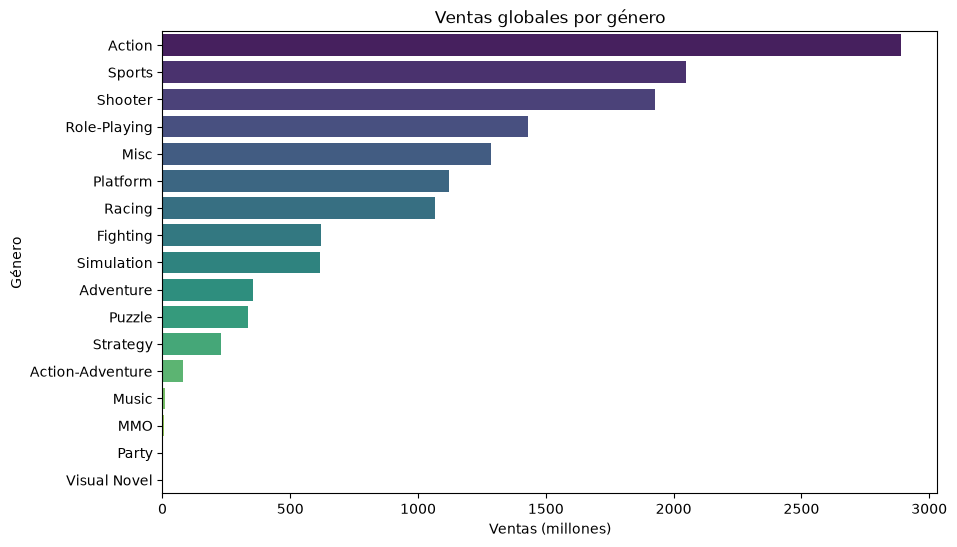

In [31]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=genre_sales['Global'],
    y=genre_sales.index,
    palette='viridis'
)

plt.title('Ventas globales por género')
plt.xlabel('Ventas (millones)')
plt.ylabel('Género')

plt.show()

Se puede ver claramente en la gráfica que los videojuegos de acción son los más vendidos, seguidos por los de deportes y disparos que están más o menos igualados.

In [36]:
'''
Ahora lo que buscamos es una distribución porcentual por región para normalizar los datos.
'''
genre_pct = (genre_sales[['North America','Europe','Japan','Rest of World']].div(genre_sales[['North America','Europe','Japan','Rest of World']].sum(axis=1),axis=0)* 100)
genre_pct

,North America,Europe,Japan,Rest of World
Genre,,,,
Action,48.766876,31.924048,8.009853,11.299224
Sports,49.980950,31.405879,7.914481,10.698690
Shooter,53.630224,32.313613,3.080945,10.975218
Role-Playing,37.204285,22.615423,32.819875,7.360417
Misc,51.376040,28.344865,10.862163,9.416932
Platform,51.912008,25.939521,14.930772,7.217698
Racing,46.626118,35.239264,6.978313,11.156304
Fighting,50.418511,23.551369,16.893966,9.136154
Simulation,45.874442,31.273811,14.302693,8.549054


Al analizar las ventas por regiones, se puede ver que Norte América vende más videojuegos en general de cualquier género, y después Europa. Aunque Japón, produce una anomalía en los videojuegos de rol, ya que clase iguala en ventas a Norte América y supera a Europa.

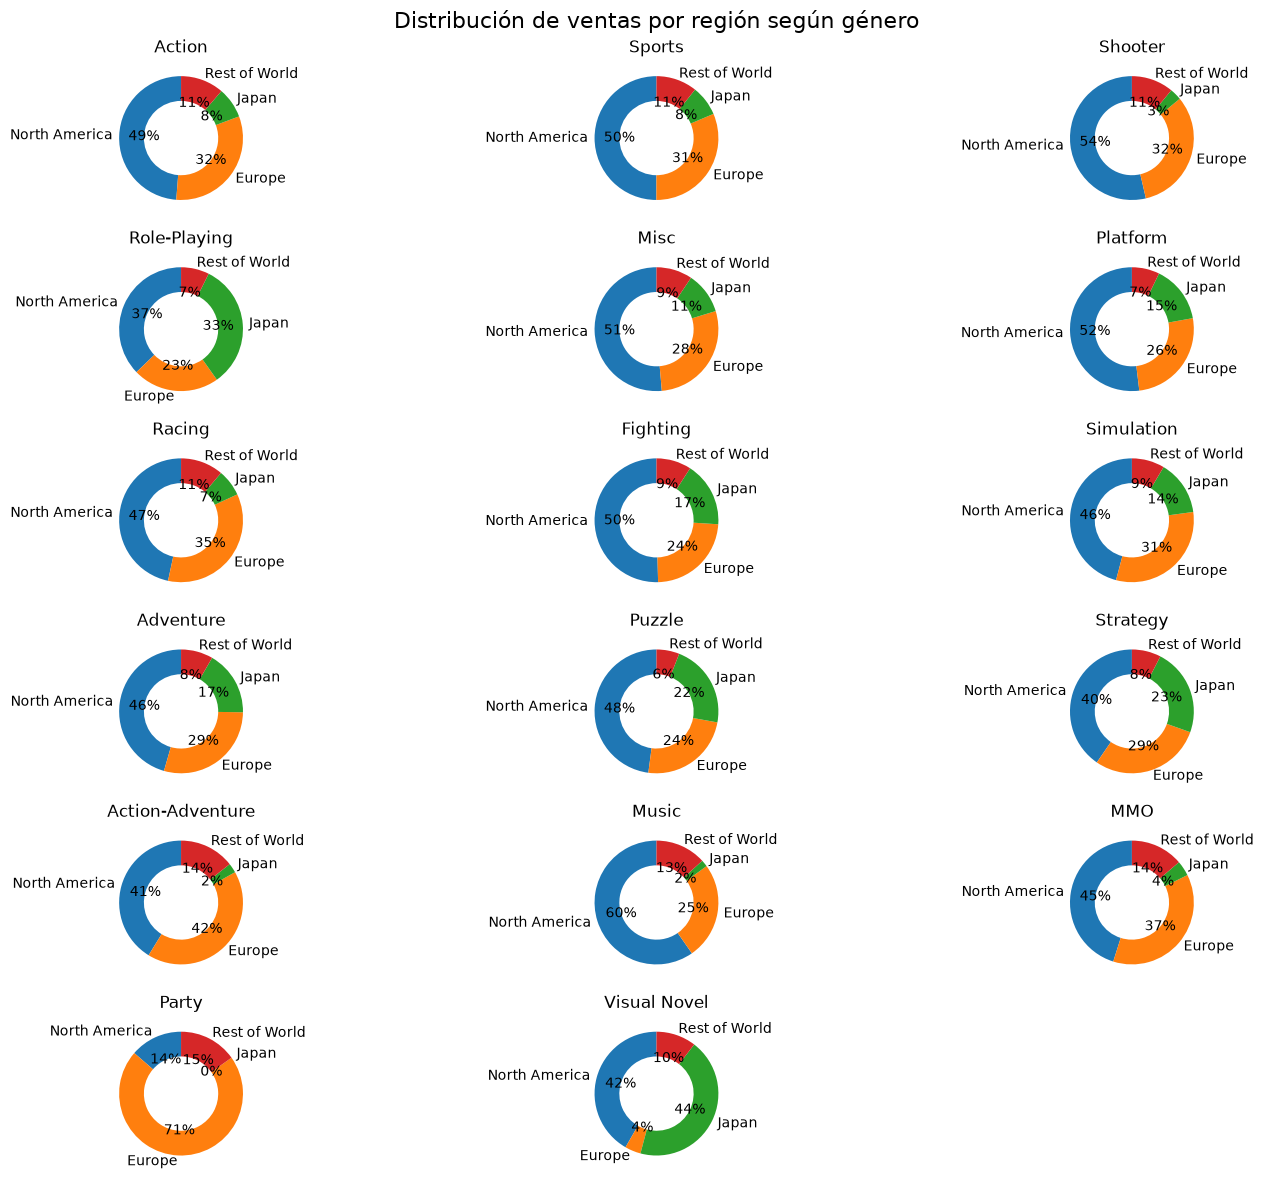

In [47]:
n_genres = len(genre_pct)

fig, axes = plt.subplots(
    nrows=(n_genres+2)//3,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, genre in enumerate(genre_pct.index):

    axes[i].pie(
        genre_pct.loc[genre],
        labels=genre_pct.columns,
        autopct='%1.0f%%',
        startangle=90,
        wedgeprops={'width':0.4}
    )

    axes[i].set_title(genre)

# Eliminar ejes vacíos
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    'Distribución de ventas por región según género',
    fontsize=16
)

plt.tight_layout()
plt.show()

En esta gráfica podemos ver, la distribución de ventas para cada género de videojuego con el porcentaje de ventas de ese género en cada región.
Podemos ver que en la mayoría de los géneros de videojuegos, Norte América lidera las ventas de los videojuegos, exceptuando el género de Party que lo lidera claramente Europa y Visual Novel y Role-Playing que tanto Norte América como Japón, tienen casi el mismo porcentaje de ventas, y en el género Action-Adventure es Norte América y Japón los que tienen casi el mismo porcentaje de ventas.

In [27]:
genre_region = (
    df.groupby('Genre')
    [['North America',
      'Europe',
      'Japan',
      'Rest of World']]
    .sum()
    .reset_index()
)
genre_region_long = genre_region.melt(
    id_vars='Genre',
    var_name='Region',
    value_name='Sales'
)

In [28]:
fig = px.treemap(
    genre_region_long,
    path=['Genre', 'Region'],
    values='Sales',
    color='Sales',
    color_continuous_scale='Blues'
)

fig.show()

## Ventas de Videojuegos por Género y Fabricante

In [31]:
genre_manufacturer = (df.groupby(['Manufacturer', 'Genre'])['Global'].sum().reset_index())

genre_manufacturer.head()

,Manufacturer,Genre,Global
0,Atari,Action,29.34
1,Atari,Adventure,1.70
2,Atari,Fighting,1.24
3,Atari,Misc,3.58
4,Atari,Platform,13.27


In [44]:
fig = px.treemap(
    genre_manufacturer,
    path=['Manufacturer', 'Genre'],
    values='Global',
    color='Global',
    color_continuous_scale='Turbo'
)

fig.show()

En esta gráfica podemos ver que las diferencias de géneros que vende cada fabricante, liderando Sony, Nintendo y Microsoft. Sony tiene un porcentaje muy alto de sus ventas en los juegos de Acción, seguidos por Deportes, Disparos, y luego por Rol y Carreras. Mientras que en Nintendo, tiene una distribución de géneros más equitativa entre los de Arcade, Simulador de Conducción, Deportes, Acción y Rol. Las ventas de Microsoft se centran en los géneros de Disparos y Acción.

In [56]:
genre_region_manufacturer = (df.groupby(['Manufacturer','Genre'])[['North America','Europe','Japan','Rest of World']].sum())

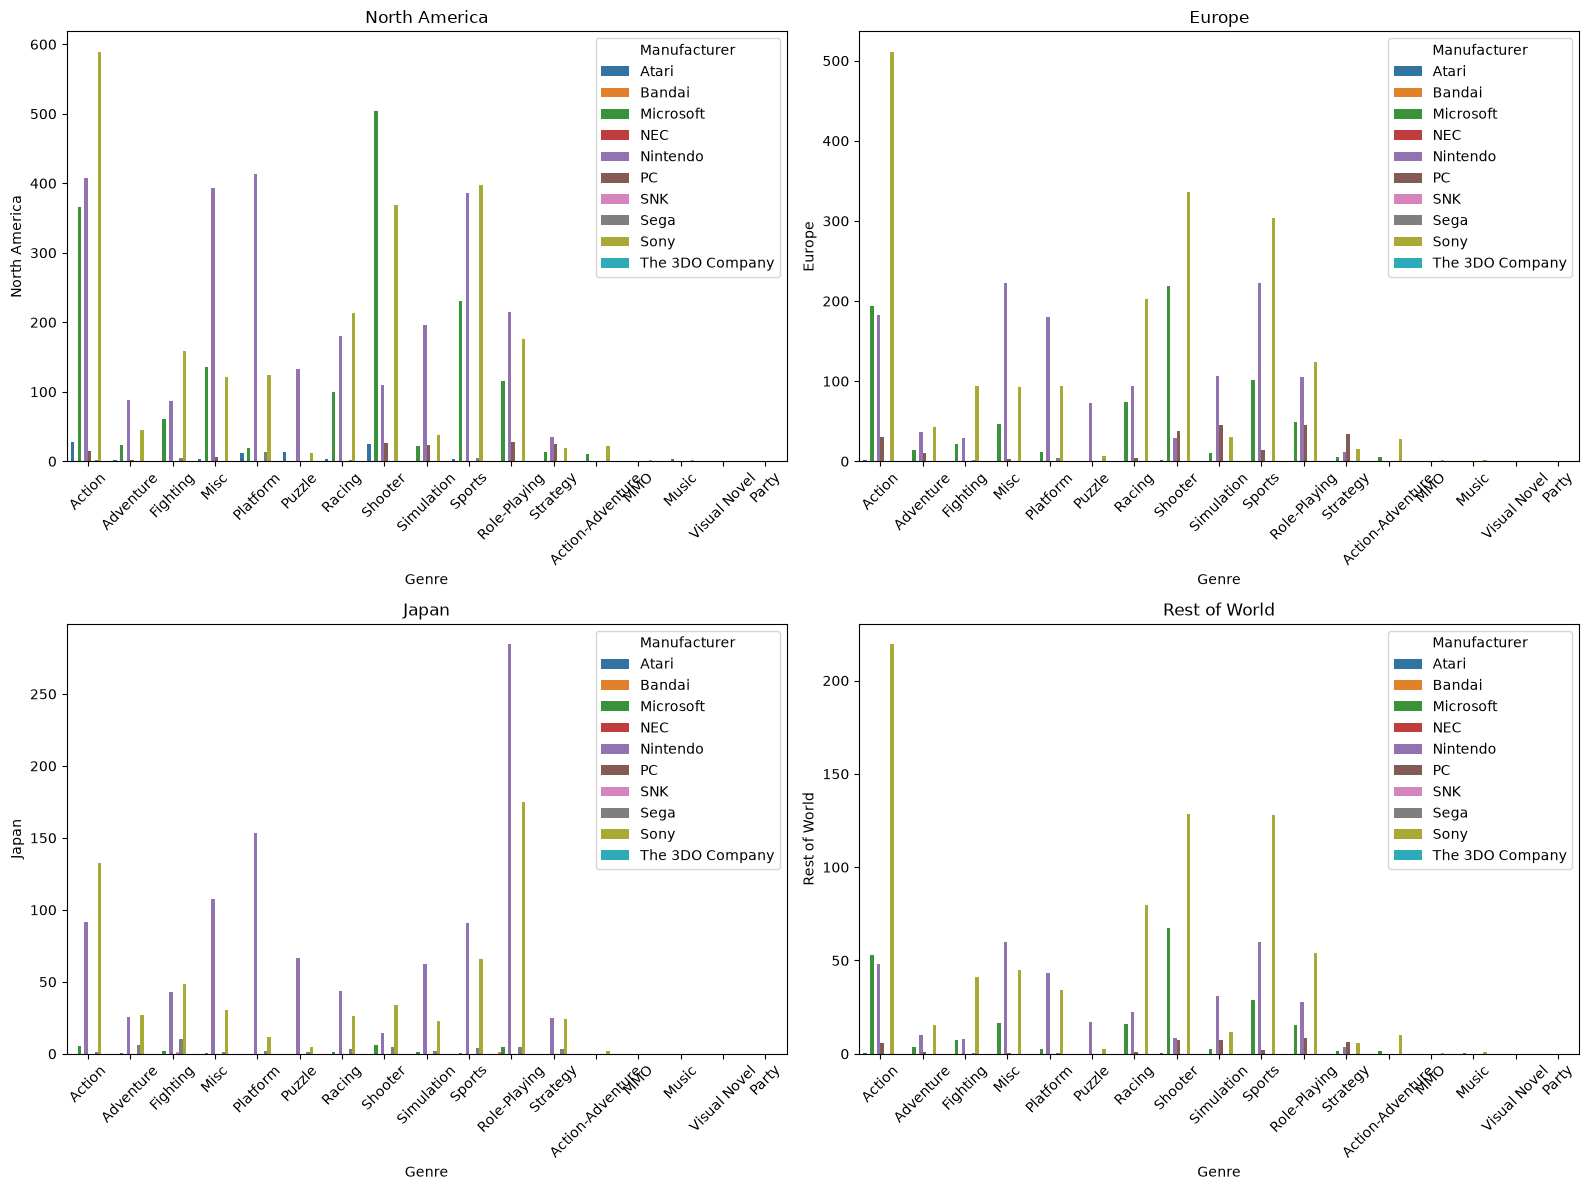

In [57]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(16,12)
)

regions = [
    'North America',
    'Europe',
    'Japan',
    'Rest of World'
]

for ax, region in zip(axes.flatten(), regions):

    data = (
        genre_region_manufacturer[region]
        .reset_index()
    )

    sns.barplot(
        data=data,
        x='Genre',
        y=region,
        hue='Manufacturer',
        ax=ax
    )

    ax.set_title(region)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Analizando las gráficas por regiones, en Norte América se puede visualizar que el género más vendido es el de Acción y que el fabricante que lo lidera es Sony. El siguiente género más vendido es el de disparos por Microsoft. Después le siguen los géneros Simuladores de Conducción, Arcade y Deportes. Los dos primeros están liderados por Nintendo, mientras que Deportes está muy igualado en ventas tanto Sony como Nintendo.
En Europa, el género más vendido también es Acción por el fabricante de Sony. Le siguen Disparos y Deportes también de Sony, y por último Arcade y Simulador de conducción por Nintendo.
Ahora podemos ver un cambio radical en la venta en Japón, ya que los juegos más vendidos son los de Rol de Nintendo. Luego le siguen los de Arcade de Nintendo, y de unas ventas similares son los Simuladores de Conducción de Nintendo y los de Acción de Sony.
En el restodel mundo podemos ver un comportamiento similar a Europa y Norte América, liderando el sector el género de Acción por el fabricante Sony, y después de forma muy igualada Disparos y Deportes también por parte de Sony.

## Ventas de Videojuegos por Género a lo Largo de Los Años a nivel Global y por Regiones

In [63]:
genre_year = (df.groupby(['Year','Genre'])['Global'].sum().reset_index())

In [88]:
sales_80_90 = (df[(df['Year']>=1980) & (df['Year']<=1999)].groupby('Genre')['Global'].sum().sort_values())
sales_00_20 = (df[(df['Year']>=2000) & (df['Year']<=2020)].groupby('Genre')['Global'].sum().sort_values())

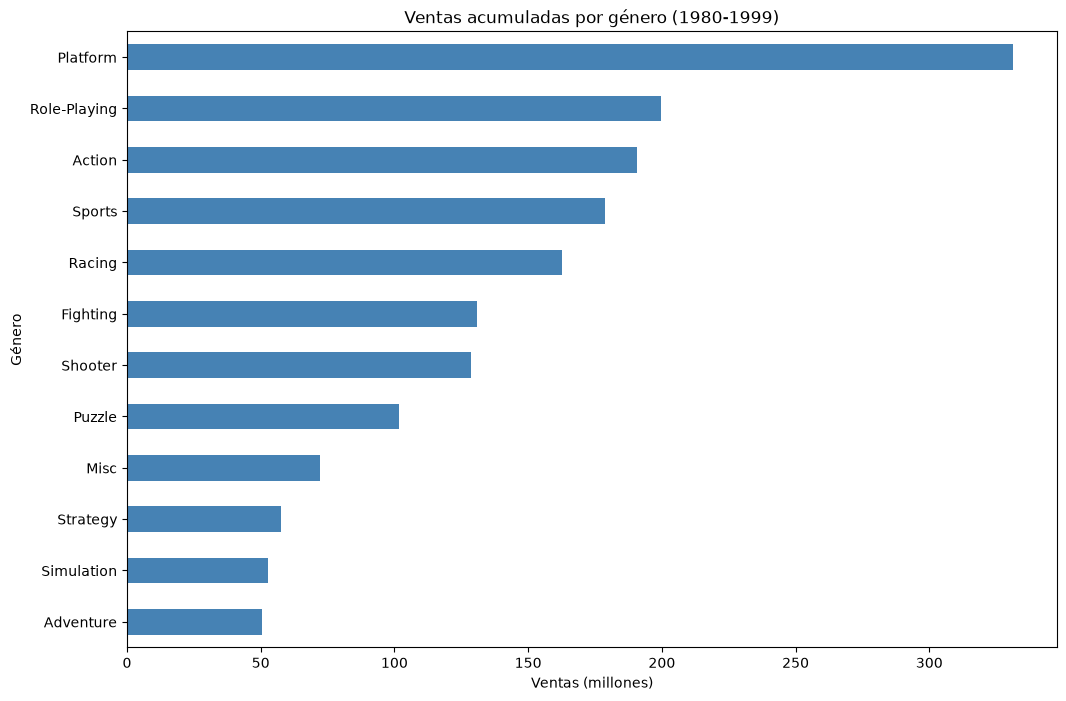

In [87]:
plt.figure(figsize=(12,8))

sales_80_90.plot(
    kind='barh',
    color='steelblue'
)

plt.title('Ventas acumuladas por género (1980-1999)')
plt.xlabel('Ventas (millones)')
plt.ylabel('Género')

plt.show()

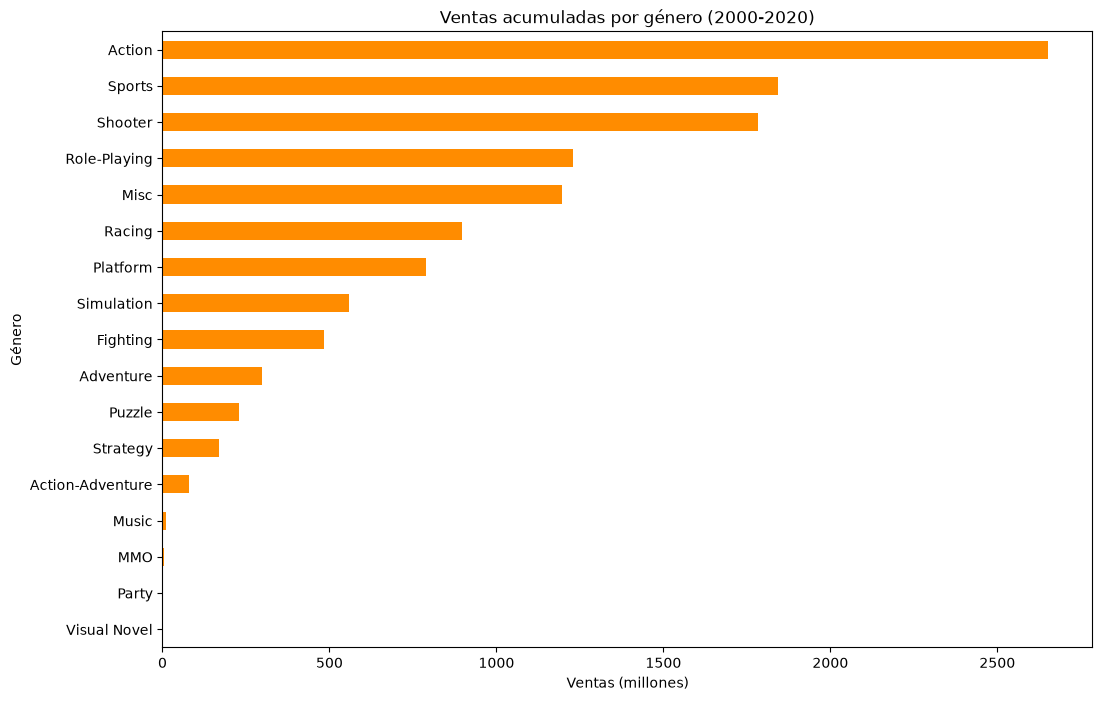

In [89]:
plt.figure(figsize=(12,8))

sales_00_20.plot(
    kind='barh',
    color='darkorange'
)

plt.title('Ventas acumuladas por género (2000-2020)')
plt.xlabel('Ventas (millones)')
plt.ylabel('Género')

plt.show()

In [90]:
periods = pd.DataFrame({
    '80-99': sales_80_90,
    '00-20': sales_00_20
}).fillna(0)

periods = periods.sort_values('00-20')

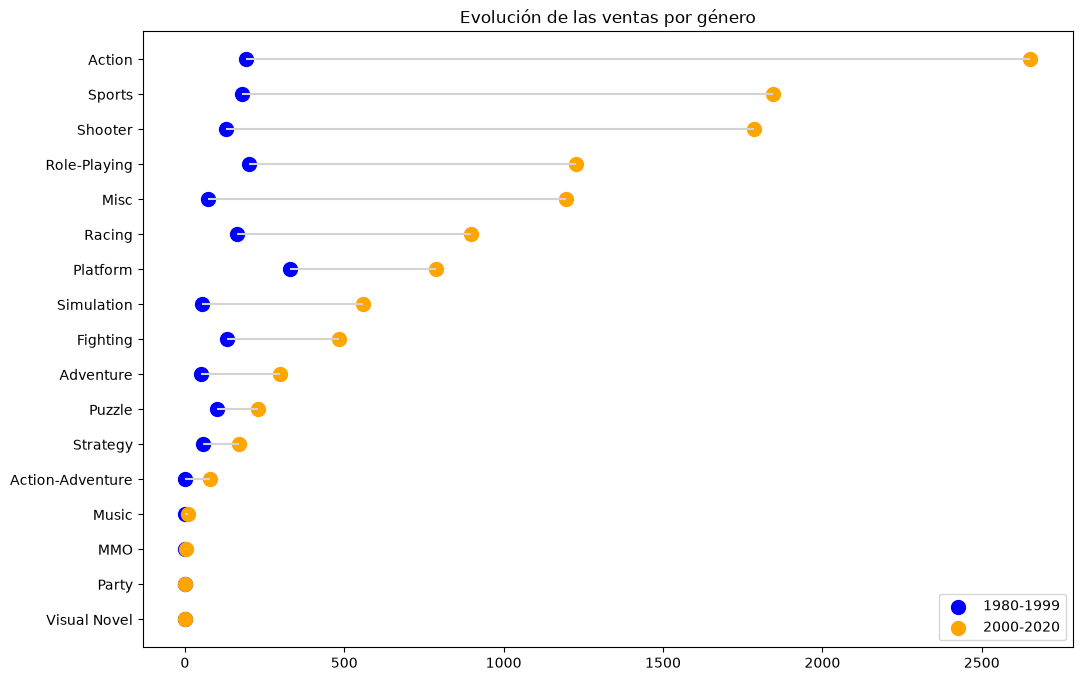

In [91]:
fig, ax = plt.subplots(figsize=(12,8))

ax.hlines(
    y=periods.index,
    xmin=periods['80-99'],
    xmax=periods['00-20'],
    color='lightgray'
)

ax.scatter(
    periods['80-99'],
    periods.index,
    color='blue',
    s=100,
    label='1980-1999'
)

ax.scatter(
    periods['00-20'],
    periods.index,
    color='orange',
    s=100,
    label='2000-2020'
)

ax.legend()

plt.title(
    'Evolución de las ventas por género'
)

plt.show()

En las decadas de los 80s y 90s, se puede ver la predominancia de ventas de los juegos de Arcade a nivel global. Y después, de una forma más igualada se puede ver las ventas de los juegos de Rol y Acción; Deportes, y Carreras; y Peleas y Disparos.
Sin embargo, podemos ver un cambio radical de la ventas de género en las décadas de los 2000s, donde predomina claramente el género de Acción; seguidas por Deportes y Disparos; y por Rol y Simuladores de Conducción.

En este último gráfico se puede ver la evolución de las ventas por género en los años 80s y 90s vs. las décadas de los 2000s.
Las ventas de videojuegos globales eran mucho menores en los años 80s y 90s que en la décadas de los 2000s. Esto es debido a la gran evolución que las consolas en los años 2000s tanto a nivel gráfico como de rápidez. Eso también hace posible el cambio de género de una época a otra, ya que está muchísimo mejor conseguidos los videojuegos y las consolas son mucho más potentes. Por lo que aunque se disparan las ventas de videojuegos en las décadas de los 2000s, la mayor diferencia de ventas se producen en los géneros de Acción, Deportes y Disparos.

In [95]:
def treemap_generos_region(df, region, year_start, year_end):

    sales = (
        df[
            (df['Year'] >= year_start) &
            (df['Year'] <= year_end)
        ]
        .groupby('Genre')[region]
        .sum()
        .reset_index()
    )

    fig = px.treemap(
        sales,
        path=['Genre'],
        values=region,
        color=region,
        color_continuous_scale='Viridis'
    )

    fig.update_traces(
        textinfo='label+percent root'
    )

    fig.update_layout(
        title=f'{region} ({year_start}-{year_end})'
    )

    fig.show()

In [96]:
treemap_generos_region(
    df,
    'North America',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Europe',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Japan',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Rest of World',
    1980,
    1999
)

En los 80s y 90s, podemos ver que Norte América y Europa tienen un comportamiento parecido en las ventas de videojuegos por género siendo Arcade y Acción. Mientras que en Japón dominaba los juegos de Rol y Arcade. Las ventas en el Resto del Mundo se centraban en Arcade y Rol.

In [97]:
treemap_generos_region(
    df,
    'North America',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Europe',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Japan',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Rest of World',
    2000,
    2020
)

En las décadas de los 2000s, se ve un cambio en las ventas por género por regiones. Norte América y Europa tienen las mismas tendencias: Acción, Deportes y Disparos. Mientras que Japón, sigue manteniendo las ventas en los juegos de Rol mayoritariamente, y después Acción. En el Resto del Mundo, también hay un cambio de ventas en el Resto del Mundo cambiando a los géneros de Acción y Deportes.